# Music Popularity Capstone

**Group name:** Four (4)    **Your genre:** drum-and-bass    **Date:** 5th October, 2026

We are the data team at a music streaming service. The A&R department wants to know three things:

1. **What makes a track popular?** — a regression problem
2. **Can we spot a hit before it charts?** — a classification problem
3. **What moods exist inside a genre?** — a clustering problem


| Part | Weeks |
|---|---|
| 1. Load the data | 1–2 |
| 2. Clean it | 3 |
| 3. Explore it | 4 |
| 4. Predict popularity (regression) | 5 |
| 5. Spot the hits (classification) | 6 |
| 6. Find moods (clustering) | 7 |
| 7. Tune and finish | 7 |
| 8. Write it up | 8 |


**Use of an AI assistant:** we used an AI assistant (Claude) to explain errors and concepts and to help draft code and wording. We checked every result against our own outputs and we can explain every cell.

---
## Part 1 — Setup and load the data

**Week 1-2**

### 1.1 Import the libraries

Every later part uses these tools, so we load them once at the top.

In [97]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (train_test_split, cross_val_score, GroupKFold,
                                     GroupShuffleSplit, GridSearchCV)
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.dummy import DummyRegressor
from sklearn.metrics import (mean_squared_error, r2_score, accuracy_score, precision_score,
                             recall_score, confusion_matrix, ConfusionMatrixDisplay, silhouette_score)
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

sns.set_theme(style="whitegrid")

import sklearn
print("pandas", pd.__version__, "| numpy", np.__version__, "| scikit-learn", sklearn.__version__)

pandas 2.2.2 | numpy 1.26.4 | scikit-learn 1.5.1


### 1.2 Settings

In [98]:
RANDOM_STATE = 42   # leave this alone

features = ["danceability","energy","valence","acousticness","instrumentalness",
            "liveness","speechiness","loudness","tempo","duration_ms"]

print("Random seed:", RANDOM_STATE)
print("Number of audio features:", len(features))

Random seed: 42
Number of audio features: 10


### 1.3 Load the dataset

This reads the file once and keeps an untouched copy (df_raw). Every later cleaning step starts from it, so you can always show what you began with and a fresh run always gives the same data. The Unnamed: 0 column is a leftover row index from the CSV, so it is dropped to stop it sneaking into the models.

In [99]:
df_raw = pd.read_csv("spotify_tracks.csv").drop(columns=["Unnamed: 0"])
print(df_raw.shape)
df_raw.head()

(114000, 20)


,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,1,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,1,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,0,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Soundtrack),Can't Help Falling In Love,71,201933,False,0.266,0.0596,0,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,2,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


### 1.4 Dataset Inspection
Checking its size, missing values and repeats.

In [100]:
print("Genres:", df_raw.track_genre.nunique())
print("Tracks per genre (min / max):", df_raw.track_genre.value_counts().min(), "/", df_raw.track_genre.value_counts().max())

print("\nColumns with missing values:")
missing = df_raw.isna().sum()
print(missing[missing > 0])

print("\nRepeated track_ids across the whole file:", df_raw.track_id.duplicated().sum())
print("Same track repeated inside one genre (same track_id):", df_raw.duplicated(subset=["track_id", "track_genre"]).sum())
print("Same song repeated inside one genre (same title and artist):", df_raw.duplicated(subset=["track_genre", "track_name", "artists"]).sum())

print("\nPopularity of zero:", (df_raw.popularity == 0).sum(), "tracks,",
      round((df_raw.popularity == 0).mean() * 100, 1), "% of the file")

Genres: 114
Tracks per genre (min / max): 1000 / 1000

Columns with missing values:
artists       1
album_name    1
track_name    1
dtype: int64

Repeated track_ids across the whole file: 24259
Same track repeated inside one genre (same track_id): 450
Same song repeated inside one genre (same title and artist): 13790

Popularity of zero: 16020 tracks, 14.1 % of the file


### 1.5 Remove repeated songs for the genre comparison

We want our genre to be chosen from evidence and not taste. We remove repeated songs inside each genre first, because the same song on several albums would otherwise inflate counts. This works on a copy (df_all), so df_raw stays untouched.

In [101]:
key = ["track_genre", "track_name", "artists"]

df_all = (df_raw.sort_values("popularity", ascending=False)
                .drop_duplicates(subset=key, keep="first")
                .sort_index())

print("Rows before:", len(df_raw))
print("Rows after: ", len(df_all))
print("Removed:    ", len(df_raw) - len(df_all))

counts = df_all.track_genre.value_counts()
print("\nTracks per genre after removing repeats:")
print(counts.describe().round(1))
print("\nSmallest genres:")
print(counts.sort_values().head(5))

Rows before: 114000
Rows after:  100210
Removed:     13790

Tracks per genre after removing repeats:
count    114.0
mean     879.0
std      119.1
min      481.0
25%      832.2
50%      935.5
75%      956.0
max      996.0
Name: count, dtype: float64

Smallest genres:
track_genre
jazz         481
dance        494
rock         575
latin        580
reggaeton    597
Name: count, dtype: int64


### 1.6 Compare all genres

This builds one row per genre with five measures: how many unique tracks it has, how spread out its popularity is, how many tracks are hits, how many have zero plays and how different its sound is from the dataset average (the "distinctiveness" score). The last measure turns "what makes your genre different?" into a number. The scaler here is only used to describe genres, not to train a model, so there is no leakage.

In [102]:
summary = (df_all.groupby("track_genre")
           .agg(n_tracks=("track_id", "count"),
                pop_mean=("popularity", "mean"),
                pop_std=("popularity", "std"),
                pct_zero_pop=("popularity", lambda s: (s == 0).mean()),
                pct_hits=("popularity", lambda s: (s >= 70).mean())))

# How far is each genre's sound from the dataset average? (in standard deviations)
sc_all = StandardScaler().fit(df_all[features])
z = pd.DataFrame(sc_all.transform(df_all[features]), columns=features)
z["track_genre"] = df_all["track_genre"].values
summary["distinctiveness"] = z.groupby("track_genre")[features].mean().abs().sum(axis=1)

# First filter: enough tracks, real spread in popularity, enough hits, few zero-play tracks
shortlist = summary[(summary.n_tracks >= 600) & (summary.pop_std >= 12) &
                    (summary.pct_hits.between(0.08, 0.40)) & (summary.pct_zero_pop < 0.15)]

print(len(shortlist), "of", len(summary), "genres pass the first filter")
display(shortlist.sort_values("distinctiveness", ascending=False).round(2))

13 of 114 genres pass the first filter


,n_tracks,pop_mean,pop_std,pct_zero_pop,pct_hits,distinctiveness
track_genre,,,,,,
metal,828,51.11,26.09,0.12,0.26,3.87
grunge,857,52.08,16.46,0.02,0.11,3.81
punk,870,43.41,18.61,0.07,0.10,3.70
singer-songwriter,788,46.46,23.32,0.11,0.14,3.62
songwriter,788,46.46,23.32,0.11,0.14,3.62
hip-hop,733,50.15,28.20,0.12,0.18,3.48
funk,789,39.84,22.73,0.15,0.09,3.47
hard-rock,854,47.70,21.93,0.07,0.17,3.15
emo,922,50.44,14.62,0.02,0.08,2.49


### 1.7 Test every genre, with artists kept apart

The first question from the A&R team is whether audio alone can explain popularity. A genre where audio explains nothing leaves you little to analyse, so we score every genre with enough tracks using the same test. "Artists kept apart" means each artist's tracks go entirely into training or entirely into testing. Without that, the model can learn "this sounds like Artist X" instead of "this sound is popular", and the score looks better than it is. The baseline column is a model that always predicts the average, so you can see whether the real model beats guessing. Tracks with zero popularity are left out here, because Part 2 will remove them too.

In [103]:
rows = []
eligible = summary[summary.n_tracks >= 600].index
print("Genres to test:", len(eligible), "(this takes a few minutes)")

for g in eligible:
    d = df_all[(df_all.track_genre == g) & (df_all.popularity > 0)].copy()
    d["lead_artist"] = d.artists.str.split(";").str[0]
    if d.lead_artist.nunique() < 40:        # too few artists for a fair grouped split
        continue
    cv = GroupKFold(n_splits=5)
    rf_ = RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)
    r2 = cross_val_score(rf_, d[features], d.popularity, cv=cv, groups=d.lead_artist, scoring="r2")
    base = cross_val_score(DummyRegressor(), d[features], d.popularity, cv=cv, groups=d.lead_artist, scoring="r2")
    top5_share = d.lead_artist.value_counts().head(5).sum() / len(d)
    rows.append((g, len(d), d.lead_artist.nunique(), round(top5_share, 2),
                 round(d.popularity.std(), 1), round(r2.mean(), 3), round(r2.std(), 3), round(base.mean(), 3)))

screen = pd.DataFrame(rows, columns=["genre", "n_rows", "n_artists", "top5_artist_share",
                                     "pop_std", "grouped_R2", "R2_std", "baseline_R2"])
screen = screen.sort_values("grouped_R2", ascending=False).reset_index(drop=True)

print(len(screen), "genres tested")
display(screen.head(15))
print("\nOur choice:")
display(screen[screen.genre == GENRE if "GENRE" in globals() else screen.genre == "drum-and-bass"])

Genres to test: 108 (this takes a few minutes)
108 genres tested


,genre,n_rows,n_artists,top5_artist_share,pop_std,grouped_R2,R2_std,baseline_R2
0,sleep,790,281,0.23,13.1,0.423,0.123,-0.047
1,world-music,943,83,0.43,11.3,0.290,0.119,-0.058
2,dub,898,264,0.20,10.7,0.235,0.111,-0.050
3,k-pop,898,129,0.48,12.5,0.191,0.308,-0.332
4,drum-and-bass,954,174,0.14,14.4,0.180,0.059,-0.013
5,hardcore,876,354,0.15,14.5,0.170,0.129,-0.096
6,groove,866,213,0.24,15.3,0.160,0.125,-0.159
7,rockabilly,794,178,0.34,15.0,0.158,0.049,-0.086
8,french,901,390,0.09,14.8,0.137,0.068,-0.020
9,piano,830,299,0.25,13.1,0.099,0.109,-0.031



Our choice:


,genre,n_rows,n_artists,top5_artist_share,pop_std,grouped_R2,R2_std,baseline_R2
4,drum-and-bass,954,174,0.14,14.4,0.18,0.059,-0.013


### 1.8: Re-test the finalists with repeated artist splits

One cross-validation run can flatter a genre. Here we draw ten different random artist-grouped splits for each finalist and record the average, the worst split and the "predict the average" baseline. A genre that scores well in all ten is a safer choice than one that scores well on average but fails some splits.

In [104]:
def repeated_grouped(g, n=10):
    d = df_all[(df_all.track_genre == g) & (df_all.popularity > 0)].copy()
    d["lead_artist"] = d.artists.str.split(";").str[0]
    gss = GroupShuffleSplit(n_splits=n, test_size=0.2, random_state=RANDOM_STATE)
    rf_scores, base_scores = [], []
    for tr, te in gss.split(d, groups=d.lead_artist):
        Xtr, Xte = d.iloc[tr][features], d.iloc[te][features]
        ytr, yte = d.iloc[tr].popularity, d.iloc[te].popularity
        rf_ = RandomForestRegressor(n_estimators=150, random_state=RANDOM_STATE, n_jobs=-1).fit(Xtr, ytr)
        rf_scores.append(r2_score(yte, rf_.predict(Xte)))
        base_scores.append(r2_score(yte, DummyRegressor().fit(Xtr, ytr).predict(Xte)))
    return {"genre": g, "n_rows": len(d), "n_artists": d.lead_artist.nunique(),
            "RF_R2_mean": round(np.mean(rf_scores), 3), "RF_R2_std": round(np.std(rf_scores), 3),
            "RF_R2_worst": round(np.min(rf_scores), 3), "baseline_R2": round(np.mean(base_scores), 3)}

finalists = ["drum-and-bass", "dub", "hardcore", "sleep"]
stability = pd.DataFrame([repeated_grouped(g) for g in finalists]).sort_values("RF_R2_mean", ascending=False)
display(stability)

,genre,n_rows,n_artists,RF_R2_mean,RF_R2_std,RF_R2_worst,baseline_R2
3,sleep,790,281,0.421,0.206,-0.006,-0.017
1,dub,898,264,0.222,0.106,0.056,-0.040
2,hardcore,876,354,0.219,0.110,0.049,-0.046
0,drum-and-bass,954,174,0.194,0.083,0.022,-0.026


### 1.9: Label-quality check on the three finalists

In [105]:
def label_check(g):
    d = df_all[df_all.track_genre == g].copy()
    d["lead_artist"] = d.artists.str.split(";").str[0]
    print("\n====", g, "|", len(d), "tracks |", d.lead_artist.nunique(), "artists")
    display(d.lead_artist.value_counts().head(10).rename("tracks").to_frame()
            .join(d.groupby("lead_artist").popularity.median().rename("median_pop")))
    display(d[["tempo", "energy", "instrumentalness", "acousticness", "speechiness", "duration_ms"]]
            .quantile([.1, .5, .9]).round(2))
    print("Mostly instrumental (>0.5):", round((d.instrumentalness > 0.5).mean(), 2),
          "| mostly vocal (<0.1):", round((d.instrumentalness < 0.1).mean(), 2),
          "| tempo under 100:", round((d.tempo < 100).mean(), 2))

for g in ["drum-and-bass", "hardcore", "dub"]:
    label_check(g)


==== drum-and-bass | 954 tracks | 174 artists


,tracks,median_pop
lead_artist,,
Chase & Status,37,23.0
Pendulum,28,48.0
Netsky,25,40.0
Hybrid Minds,22,21.0
Sub Focus,20,50.5
Friction,19,48.0
Wilkinson,18,19.5
High Contrast,17,19.0
DJ Fresh,17,47.0


,tempo,energy,instrumentalness,acousticness,speechiness,duration_ms
0.1,87.50,0.73,0.00,0.00,0.04,201078.8
0.5,173.92,0.90,0.29,0.00,0.06,270512.0
0.9,175.00,0.98,0.88,0.07,0.20,359619.2


Mostly instrumental (>0.5): 0.42 | mostly vocal (<0.1): 0.41 | tempo under 100: 0.13

==== hardcore | 952 tracks | 377 artists


,tracks,median_pop
lead_artist,,
Los Prisioneros,34,35.0
The Notorious B.I.G.,32,61.5
For Revenge,25,36.0
Nas,24,61.0
Dead Fish,22,31.5
Eterna Inocencia,16,32.5
Seringai,14,31.5
Bayside,12,31.0
Millencolin,10,33.5


,tempo,energy,instrumentalness,acousticness,speechiness,duration_ms
0.1,90.03,0.61,0.00,0.00,0.04,119614.0
0.5,117.95,0.90,0.00,0.01,0.11,211011.5
0.9,175.01,0.99,0.23,0.20,0.32,289948.8


Mostly instrumental (>0.5): 0.06 | mostly vocal (<0.1): 0.87 | tempo under 100: 0.33

==== dub | 941 tracks | 268 artists


,tracks,median_pop
lead_artist,,
ILLENIUM,81,51.0
BaianaSystem,37,33.0
SLANDER,27,51.0
Tritonal,25,21.0
Seven Lions,23,48.0
Porter Robinson,22,51.0
Krewella,21,46.0
Said The Sky,18,45.0
Cidade Verde Sounds,16,29.0


,tempo,energy,instrumentalness,acousticness,speechiness,duration_ms
0.1,80.96,0.47,0.00,0.00,0.03,166489.0
0.5,136.04,0.72,0.00,0.05,0.06,223511.0
0.9,164.92,0.94,0.41,0.37,0.22,304390.0


Mostly instrumental (>0.5): 0.09 | mostly vocal (<0.1): 0.83 | tempo under 100: 0.22


### 1.10a OUR CHOSEN GENRE (drum-and-bass)

In [106]:
GENRE = 'drum-and-bass'   # chosen after comparing all genres (see "How we chose our genre")

print(f'Working on: {GENRE}')
print("Unique tracks in this genre:", (df_all.track_genre == GENRE).sum())

Working on: drum-and-bass
Unique tracks in this genre: 954


### 1.10b: Evidence for the genres we rejected

The notes below say k-pop and german were rejected because their labels mixed different kinds of music. This cell shows the evidence: the biggest artists in each genre and how many k-pop tracks come from Indian film and devotional artists. The artist list was picked by hand from the artist names.

In [107]:
for g in ["k-pop", "german"]:
    label_check(g)

kp = df_all[df_all.track_genre == "k-pop"].copy()
kp["lead_artist"] = kp.artists.str.split(";").str[0]
not_kpop = ["Yuvan Shankar Raja", "Alka Yagnik", "Jubin Nautiyal", "Anuradha Paudwal", "Ilaiyaraaja",
            "Vijay Antony", "Vidyasagar", "Dhanush", "Jagjit Singh", "Anupam Roy", "Raghu Dixit",
            "T. M. Soundararajan", "Kamal Haasan", "Madhusree", "Charan Raj"]
n_out = kp.lead_artist.isin(not_kpop).sum()
print(f"k-pop label: {n_out} of {len(kp)} tracks ({n_out/len(kp):.0%}) are by Indian film or devotional artists")


==== k-pop | 908 tracks | 129 artists


,tracks,median_pop
lead_artist,,
Yuvan Shankar Raja,154,50.0
BTS,120,69.0
Alka Yagnik,63,50.0
Jubin Nautiyal,53,52.0
Anuradha Paudwal,42,47.0
Ilaiyaraaja,37,47.0
BLACKPINK,36,70.5
Vijay Antony,22,54.0
Stray Kids,22,73.5


,tempo,energy,instrumentalness,acousticness,speechiness,duration_ms
0.1,84.52,0.42,0.0,0.01,0.03,175681.6
0.5,119.95,0.71,0.0,0.21,0.05,232864.0
0.9,159.45,0.90,0.0,0.76,0.19,330120.0


Mostly instrumental (>0.5): 0.01 | mostly vocal (<0.1): 0.98 | tempo under 100: 0.28

==== german | 789 tracks | 252 artists


,tracks,median_pop
lead_artist,,
Hans Zimmer,142,29.0
Johann Sebastian Bach,39,0.0
Robert Schumann,30,0.0
Ramin Djawadi,18,57.0
Die Toten Hosen,15,38.0
Zedd,15,66.0
Robin Schulz,15,64.0
Mickie Krause,14,0.0
Ludwig van Beethoven,13,0.0


,tempo,energy,instrumentalness,acousticness,speechiness,duration_ms
0.1,79.49,0.07,0.00,0.01,0.03,123460.8
0.5,120.02,0.58,0.00,0.25,0.05,192509.0
0.9,160.04,0.91,0.92,0.96,0.29,322863.2


Mostly instrumental (>0.5): 0.34 | mostly vocal (<0.1): 0.61 | tempo under 100: 0.32
k-pop label: 454 of 908 tracks (50%) are by Indian film or devotional artists


### HOW WE CHOSE OUR GENRE

We compared all 114 genres after removing songs repeated within a genre. We scored 108 genres with at least 600 unique tracks on how well audio features predict popularity, keeping each artist entirely in training or testing. The four best candidates were then re-tested with ten random artist-grouped splits, and drum-and-bass, dub and hardcore were statistically tied (mean R² 0.19 to 0.22). We chose between them by checking whether the genre label held together, using the artist lists and the tempo range.

**Rejected genres and why:**

**k-pop:** 454 of its 908 tracks (50%) are by 15 Indian film and devotional artists, picked by hand from the artist names (for example Yuvan Shankar Raja with 154 tracks and Alka Yagnik with 63). These artists have a median popularity of 47 to 54, against 69 to 74 for BTS, BLACKPINK and Stray Kids, so the label mixes two very different audiences. 28% of the genre's tracks are under 100 BPM. Its score also swung a lot between splits (a spread of 0.31 in Part 1.7).

**german:** Hans Zimmer alone is 142 of its 789 tracks (18%). The other biggest artists are classical composers (Bach, Schumann and Beethoven, all with a median popularity of 0), a film composer (Ramin Djawadi), dance acts (Zedd, Robin Schulz), a German party singer (Mickie Krause, median 0), a rock band (Die Toten Hosen) and a rap group (K.I.Z). Mostly instrumental tracks are 34% of the genre and mostly vocal ones 61%, so this is not one musical scene.

**hardcore**: hardcore rap (The Notorious B.I.G., Nas) mixed with punk and rock, and a third of tracks under 100 BPM.

**dub**: melodic EDM (ILLENIUM, 81 tracks, SLANDER, Seven Lions) mixed with Brazilian and reggae dub.

**sleep**: highest score (R² 0.42) but unstable (worst split -0.006) and far above the normal range for audio-only prediction.

**world-music**: only 83 artists, with the top five taking 43% of tracks, and a catch-all label.

**drum-and-bass** has a coherent artist list, a tight tempo around 174 BPM, 174 artists and a stable positive score. Its mix of instrumental and vocal tracks is a natural structure for the mood clusters.

### 1.11: Filter to your genre

In [108]:
df_genre = df_all[df_all.track_genre == GENRE].copy()
df_genre["lead_artist"] = df_genre.artists.str.split(";").str[0]

print(df_genre.shape[0], "tracks |", df_genre.lead_artist.nunique(), "lead artists")
df_genre[["track_name", "artists", "popularity"] + features].head()

954 tracks | 174 lead artists


,track_name,artists,popularity,danceability,energy,valence,acousticness,instrumentalness,liveness,speechiness,loudness,tempo,duration_ms
27000,Find Me,Sigma;Birdy,55,0.584,0.805,0.2380,0.0649,0.0000,0.1030,0.0465,-4.029,134.882,204444
27001,Used To This,Wilkinson;Issey Cross,20,0.686,0.756,0.3450,0.0314,0.0234,0.1540,0.0374,-3.888,87.004,226206
27002,I Don’t Even Know You Anymore (feat. Bazzi & Lil Wayne),Netsky;Bazzi;Lil Wayne,51,0.709,0.784,0.5840,0.2300,0.0000,0.1470,0.1000,-3.182,97.007,167600
27003,Dreams,NERO;ZHU,46,0.521,0.550,0.0391,0.0029,0.1710,0.0955,0.0709,-6.222,184.018,268043
27004,Supersonic (VIP),Noisia;Skrillex;josh pan;Dylan Brady,48,0.416,0.506,0.0613,0.0404,0.0202,0.1100,0.1000,-7.885,172.028,206010


### 1.12: How drum-and-bass differs from the other genres

This gives three observations for the Part 1 hand-in, and the answer to the question; "what makes your genre different?" Medians are used instead of means, because a few extreme tracks can distort an average. The second table shows the same differences in standard deviations, so features measured on different scales (tempo in BPM, danceability from 0 to 1) can be compared fairly.

In [109]:
others = df_all[df_all.track_genre != GENRE]

cmp = pd.DataFrame({
    "drum-and-bass (median)": df_genre[features + ["popularity"]].median(),
    "other genres (median)": others[features + ["popularity"]].median(),
})
cmp["difference"] = cmp["drum-and-bass (median)"] - cmp["other genres (median)"]
display(cmp.round(3))

print("\nHow far drum-and-bass sits from the dataset average (in standard deviations):")
display(z[z.track_genre == GENRE][features].mean().sort_values().round(2))

print("\nShare of tracks at popularity 70 or above:",
      round((df_genre.popularity >= 70).mean(), 3), "vs", round((others.popularity >= 70).mean(), 3))
print("Share of tracks with zero popularity:",
      round((df_genre.popularity == 0).mean(), 3), "vs", round((others.popularity == 0).mean(), 3))

,drum-and-bass (median),other genres (median),difference
danceability,0.529,0.576,-0.047
energy,0.904,0.681,0.223
valence,0.280,0.453,-0.172
acousticness,0.003,0.178,-0.175
instrumentalness,0.293,0.000,0.293
liveness,0.147,0.132,0.015
speechiness,0.059,0.049,0.010
loudness,-3.922,-7.170,3.248
tempo,173.920,122.022,51.898
duration_ms,270512.000,214786.000,55726.000



How far drum-and-bass sits from the dataset average (in standard deviations):


acousticness       -0.87
valence            -0.56
danceability       -0.15
liveness            0.03
speechiness         0.06
duration_ms         0.45
instrumentalness    0.66
loudness            0.82
energy              0.92
tempo               1.10
dtype: float64


Share of tracks at popularity 70 or above: 0.0 vs 0.053
Share of tracks with zero popularity: 0.0 vs 0.077


### Three observations

1. Drum-and-bass is a niche genre: its median popularity is 19, against 38 for the other genres and no track reaches 70.

2. It is loud and intense, with almost no acoustic sound: median energy is 0.90 (other genres 0.68), loudness is -3.9 dB (other genres -7.2 dB) and acousticness is 0.003 (other genres 0.178).

3. It is fast and mostly dark in mood: median tempo is 174 BPM (other genres 122 BPM) and median valence is 0.28 on the 0-to-1 scale (other genres 0.45).

### 1.13a: Checking Popularity and tempo before cleaning

Two decisions in Part 2 depend on what the data looks like. The first is how to define a hit (the exact popularity numbers). 
    
The second is the tempo problem, where we need to see how many tracks look half-time and where the line between "half-time" and "genuinely slow" falls, before changing any value.

count    954.0
mean      26.8
std       14.4
min        7.0
25%       17.0
50%       19.0
75%       39.0
max       69.0
Name: popularity, dtype: float64
Highest popularity: 69
Tracks at 40 or above: 235
Tracks at 50 or above: 129
Tracks at 60 or above: 14
Tracks at 70 or above: 0
75th percentile (candidate 'hit' line): 39.0


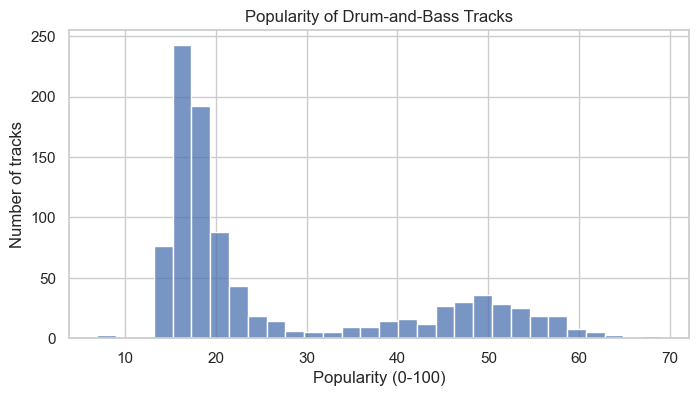


Tracks per tempo band:
tempo
(0, 60]         0
(60, 75]        1
(75, 85]       15
(85, 95]      108
(95, 105]       9
(105, 120]     31
(120, 150]     92
(150, 165]     38
(165, 185]    660
(185, 250]      0
Name: count, dtype: int64


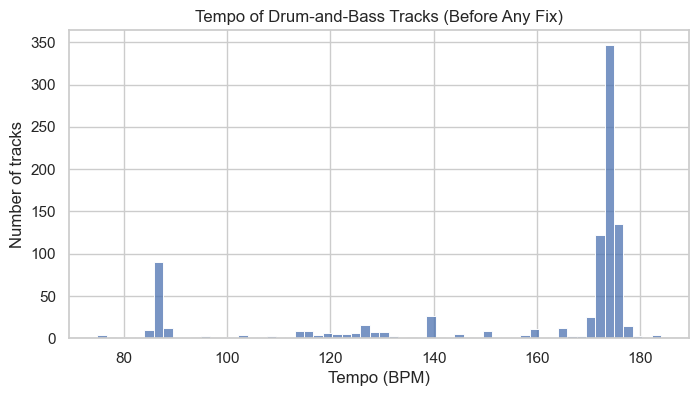

,track_name,artists,tempo
27603,Sugar,Fred V & Grafix,92.011
27731,Incredible Odyssey,Danny Breaks,94.979
27457,Hopelessly Coping - Hanami Remix,Wilkinson;THABO;René LaVice,95.003
27131,My Fallen Friends (Slaughtered & Sliced Remix),DJ Red;Lester Roy;Chloe Lee,95.533
27002,I Don’t Even Know You Anymore (feat. Bazzi & Lil Wayne),Netsky;Bazzi;Lil Wayne,97.007
27814,Feelings,SHY FX;T. Power,98.966
27415,Fifth Sun,Blame,101.021
27907,UK Border Patrol,Dimension,102.890
27021,After Party,Dynamite MC;Rookwood,102.998
27072,Come Alive,Pendulum,103.022


In [110]:
# 1. Popularity: how spread out, and where could a "hit" line go?
print(df_genre.popularity.describe().round(1))
print("Highest popularity:", df_genre.popularity.max())
for t in [40, 50, 60, 70]:
    print(f"Tracks at {t} or above:", (df_genre.popularity >= t).sum())
print("75th percentile (candidate 'hit' line):", df_genre.popularity.quantile(0.75))

plt.figure(figsize=(8, 4))
sns.histplot(df_genre.popularity, bins=30)
plt.title("Popularity of Drum-and-Bass Tracks")
plt.xlabel("Popularity (0-100)"); plt.ylabel("Number of tracks"); plt.show()

# 2. Tempo: how many look half-time?
bins = [0, 60, 75, 85, 95, 105, 120, 150, 165, 185, 250]
print("\nTracks per tempo band:")
print(pd.cut(df_genre.tempo, bins).value_counts().sort_index())

plt.figure(figsize=(8, 4))
sns.histplot(df_genre.tempo, bins=60)
plt.title("Tempo of Drum-and-Bass Tracks (Before Any Fix)")
plt.xlabel("Tempo (BPM)"); plt.ylabel("Number of tracks"); plt.show()

# Tracks in the grey zone, to judge by eye
display(df_genre[(df_genre.tempo >= 90) & (df_genre.tempo <= 110)]
        [["track_name", "artists", "tempo"]].sort_values("tempo").head(15))

### 1.13b: What separates the low and high popularity groups?

This compares the sound of the two groups and checks whether the same artists appear in both groups or whether popularity is mostly about who the artist is.

In [111]:
low  = df_genre[df_genre.popularity < 30]
high = df_genre[df_genre.popularity >= 40]
print("Low group:", len(low), "tracks | High group:", len(high), "tracks")

grp = pd.DataFrame({"low (<30)": low[features].median(), "high (>=40)": high[features].median()})
grp["difference"] = grp["high (>=40)"] - grp["low (<30)"]
display(grp.round(3))

art = (df_genre.groupby("lead_artist")
       .agg(tracks=("track_id", "count"), median_pop=("popularity", "median"),
            min_pop=("popularity", "min"), max_pop=("popularity", "max")))
in_both = art[(art.tracks >= 5) & (art.min_pop < 30) & (art.max_pop >= 40)]
print("Artists with 5+ tracks that appear in both groups:", len(in_both), "of", (art.tracks >= 5).sum())

Low group: 683 tracks | High group: 235 tracks


,low (<30),high (>=40),difference
danceability,0.544,0.495,-0.049
energy,0.907,0.896,-0.011
valence,0.310,0.229,-0.081
acousticness,0.002,0.008,0.005
instrumentalness,0.464,0.017,-0.447
liveness,0.153,0.137,-0.016
speechiness,0.063,0.050,-0.013
loudness,-4.061,-3.554,0.507
tempo,173.928,173.941,0.013
duration_ms,283551.000,230390.000,-53161.000


Artists with 5+ tracks that appear in both groups: 42 of 74


---
## Part 2 — Clean the data
**Week 3**

This starts from the untouched df_raw. The log below has three kinds of action: rows removed, values changed (the tempo fix) and checks that found nothing, which are still worth showing.

In [112]:
prob_cols = ["danceability","energy","valence","acousticness","instrumentalness","liveness","speechiness"]
df = df_raw[df_raw.track_genre == GENRE].copy()
df["lead_artist"] = df.artists.str.split(";").str[0]
log = []
start = len(df)

def drop(d, issue, keep, reason):
    n = len(d)
    d = d[keep]
    log.append((issue, "removed", n - len(d), reason))
    return d

df = drop(df, "Missing values",
          df[features + ["popularity", "track_name", "artists"]].notna().all(axis=1),
          "Rows without audio features or an identifiable track cannot be modelled or traced")

# Same song released more than once: keep the most popular copy
n = len(df)
df = (df.sort_values("popularity", ascending=False)
        .drop_duplicates(subset=["track_name", "artists"], keep="first").sort_index())
log.append(("Same song repeated (different release)", "removed", n - len(df),
            "Same title and artist on several albums or playlists; kept the most popular copy so a song cannot sit in both train and test"))

n = len(df); df = df.drop_duplicates(subset="track_id")
log.append(("Duplicate track_id", "removed", n - len(df), "Same Spotify track listed twice"))

df = drop(df, "Feature outside 0 to 1",
          (df[prob_cols] >= 0).all(axis=1) & (df[prob_cols] <= 1).all(axis=1),
          "These scores are defined between 0 and 1 (checked)")

df = drop(df, "Duration under 30s or over 15 min",
          (df.duration_ms > 30_000) & (df.duration_ms < 900_000),
          "Not typical single tracks; likely intros, long mixes or errors (checked)")

df = drop(df, "Tempo = 0", df.tempo > 0, "A tempo of 0 BPM means the audio analysis failed (checked)")

df = drop(df, "Popularity = 0", df.popularity > 0,
          "Zero would mean no recorded plays; checked, none in this genre, so no tracks lost")

# Half-time tempo fix: values are changed, not removed
df["tempo_was_doubled"] = (df.tempo >= 75) & (df.tempo < 92)
log.append(("Tempo detected at half speed", "doubled", int(df.tempo_was_doubled.sum()),
            "Drum-and-bass runs at about 170-180 BPM; values from 75 to 92 are about half of that, a known tempo-detection error. Doubled so tempo means the same for every track. Values from 92 to 165 were left alone because doubling would put them above the genre's range, or they look like genuinely different tempos"))
df.loc[df.tempo_was_doubled, "tempo"] = df.loc[df.tempo_was_doubled, "tempo"] * 2

cleaning_log = pd.DataFrame(log, columns=["Issue", "Action", "Rows", "Reason"])
pd.set_option("display.max_colwidth", 120)
display(cleaning_log)

,Issue,Action,Rows,Reason
0,Missing values,removed,0,Rows without audio features or an identifiable track cannot be modelled or traced
1,Same song repeated (different release),removed,46,Same title and artist on several albums or playlists; kept the most popular copy so a song cannot sit in both train ...
2,Duplicate track_id,removed,0,Same Spotify track listed twice
3,Feature outside 0 to 1,removed,0,These scores are defined between 0 and 1 (checked)
4,Duration under 30s or over 15 min,removed,1,"Not typical single tracks; likely intros, long mixes or errors (checked)"
5,Tempo = 0,removed,0,A tempo of 0 BPM means the audio analysis failed (checked)
6,Popularity = 0,removed,0,"Zero would mean no recorded plays; checked, none in this genre, so no tracks lost"
7,Tempo detected at half speed,doubled,121,"Drum-and-bass runs at about 170-180 BPM; values from 75 to 92 are about half of that, a known tempo-detection error...."


In [113]:
print(f"Rows: {start} -> {len(df)}  |  lead artists: {df.lead_artist.nunique()}")
print("\nTempo bands after the fix:")
print(pd.cut(df.tempo, [0, 100, 120, 150, 165, 185, 250]).value_counts().sort_index())

Rows: 1000 -> 953  |  lead artists: 174

Tempo bands after the fix:
tempo
(0, 100]        7
(100, 120]     36
(120, 150]     92
(150, 165]     44
(165, 185]    774
(185, 250]      0
Name: count, dtype: int64


In [114]:
display(df[features + ["popularity"]].describe().round(2))

,danceability,energy,valence,acousticness,instrumentalness,liveness,speechiness,loudness,tempo,duration_ms,popularity
count,953.00,953.00,953.00,953.00,953.00,953.00,953.00,953.00,953.00,953.00,953.00
mean,0.54,0.88,0.32,0.03,0.38,0.22,0.09,-4.17,166.28,275979.78,26.77
std,0.12,0.11,0.23,0.06,0.36,0.18,0.08,2.40,17.90,67145.27,14.41
min,0.22,0.38,0.03,0.00,0.00,0.02,0.03,-16.07,74.93,44215.00,7.00
25%,0.45,0.83,0.12,0.00,0.01,0.09,0.04,-5.42,171.97,228863.00,17.00
50%,0.53,0.90,0.28,0.00,0.30,0.15,0.06,-3.92,173.98,270464.00,19.00
75%,0.62,0.96,0.46,0.02,0.78,0.31,0.10,-2.59,174.08,314269.00,39.00
max,0.92,1.00,0.97,0.48,0.96,0.94,0.68,0.92,184.02,650640.00,69.00


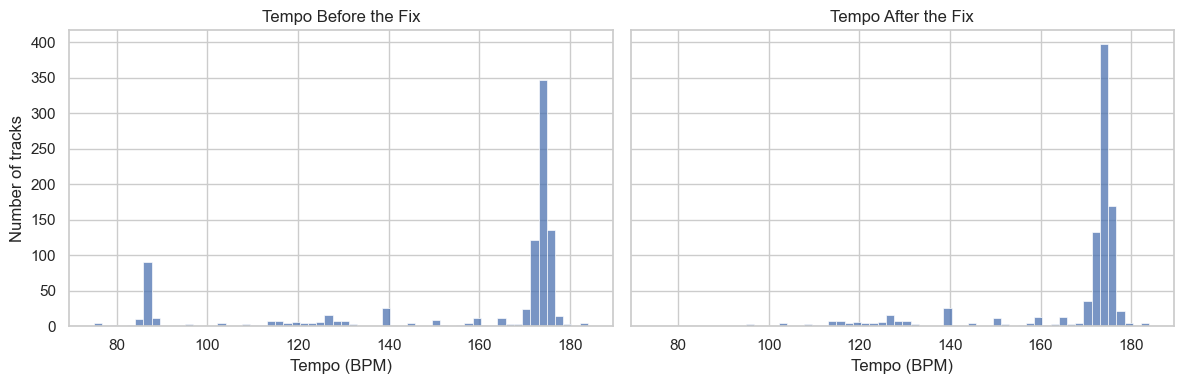

In [115]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
sns.histplot(df_genre.tempo, bins=60, ax=ax[0]); ax[0].set(title="Tempo Before the Fix", xlabel="Tempo (BPM)", ylabel="Number of tracks")
sns.histplot(df.tempo, bins=60, ax=ax[1]);       ax[1].set(title="Tempo After the Fix",  xlabel="Tempo (BPM)", ylabel="")
plt.tight_layout(); plt.show()

### New columns

We add two columns: `duration_min` (duration in minutes, easier to read than milliseconds) and `is_hit`, which is built from popularity, so it must never be used as an input to a model.

We define a hit as popularity of 40 or more. The usual line of 70 cannot be used because no drum-and-bass track reaches it (the highest is 69). The support notebook suggests the genre median, but here that is 19, which would cut straight through the large cluster of tracks at 15 to 20. Forty sits in the gap between the two groups in Chart 1 and gives 235 hits (24.7%). A hit therefore means a hit within drum-and-bass. The line is one variable (`HIT_LINE`), so it is easy to change.

In [116]:
df["duration_min"] = df["duration_ms"] / 60000

HIT_LINE = 40       
df["is_hit"] = (df["popularity"] >= HIT_LINE).astype(int)

print(df["duration_min"].describe().round(2))
print("\nHits:", df.is_hit.sum(), f"({df.is_hit.mean():.1%})  |  Not hits:", (df.is_hit == 0).sum())

count    953.00
mean       4.60
std        1.12
min        0.74
25%        3.81
50%        4.51
75%        5.24
max       10.84
Name: duration_min, dtype: float64

Hits: 235 (24.7%)  |  Not hits: 718


### Write: Cleaning log

| Step | What you found | What you did | Why |
|---|---|---|---|
| Junk column | A leftover row-number column (`Unnamed: 0`) | Dropped it | It could sneak into the models as a meaningless input |
| Duplicates | 46 songs listed under more than one release (same title and artist). No repeated track IDs | Kept the most popular copy | Re-releases on compilations often have near-zero plays. Keeping one copy stops a song sitting in both training and testing |
| Missing values | None in this genre | Checked, nothing removed | Models cannot use blank values |
| Odd values | One 71-minute continuous DJ mix. No impossible feature scores, no 0 BPM, no zero-popularity tracks. 121 tracks (13%) with tempo measured at about half speed (75 to 92 BPM) | Removed the DJ mix. Doubled the 121 tempo values | The DJ mix is not a single track. Spotify sometimes detects half-time, and drum-and-bass runs at about 170 to 180 BPM. Values from 92 to 165 BPM were left alone because doubling would put them above the genre's range or they look like genuinely different tempos |
| New columns | None in the file | Added `duration_min`, `lead_artist`, `tempo_was_doubled` and `is_hit` (popularity of 40 or more) | Easier to read, needed to keep each artist on one side of the train/test split, a record of the tempo fix, and needed for the hit question |

Result: 1,000 tracks became 953 (46 repeated songs and one DJ mix removed), from 174 lead artists.

---
## Part 3 — Explore the data
**Week 4**

Four charts. **Every chart needs a title, axis labels, and a sentence underneath saying what it shows.**

### Chart 1: Popularity of drum-and-bass tracks

This shows the two humps, and marks the line we will use to define a hit in Part 5.

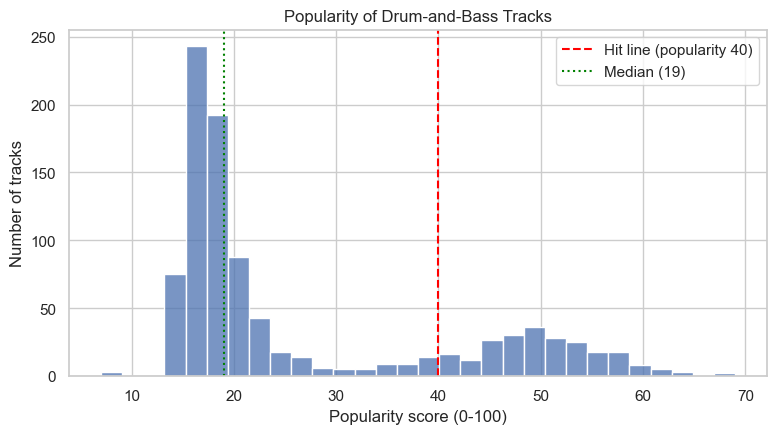

count    953.0
mean      26.8
std       14.4
min        7.0
25%       17.0
50%       19.0
75%       39.0
max       69.0
Name: popularity, dtype: float64
Tracks at 40 or above: 235 (24.7%)
Tracks below 30: 682 (71.6%)


In [117]:
plt.figure(figsize=(9, 4.5))
sns.histplot(df.popularity, bins=30, color="#4C72B0")
plt.axvline(40, color="red", linestyle="--", label="Hit line (popularity 40)")
plt.axvline(df.popularity.median(), color="green", linestyle=":", label=f"Median ({df.popularity.median():.0f})")
plt.title("Popularity of Drum-and-Bass Tracks")
plt.xlabel("Popularity score (0-100)")
plt.ylabel("Number of tracks")
plt.legend(); plt.show()

print(df.popularity.describe().round(1))
print("Tracks at 40 or above:", (df.popularity >= 40).sum(), f"({(df.popularity >= 40).mean():.1%})")
print("Tracks below 30:", (df.popularity < 30).sum(), f"({(df.popularity < 30).mean():.1%})")

**What this shows:**

Popularity falls into two groups: 682 tracks (71.6%) score below 30, clustered around 15 to 20 and 235 tracks (24.7%) score 40 or above, with few tracks in between. The median is 19 and no track exceeds 69. This means the streaming service should judge drum-and-bass tracks against each other and not against chart-style benchmarks, because even the most popular track in the genre peaks at 69.

### Chart 2: Which features move with popularity

This answers the A&R team's first question directly. Spearman correlation is used because it handles the skewed features (instrumentalness, acousticness) better than ordinary correlation.

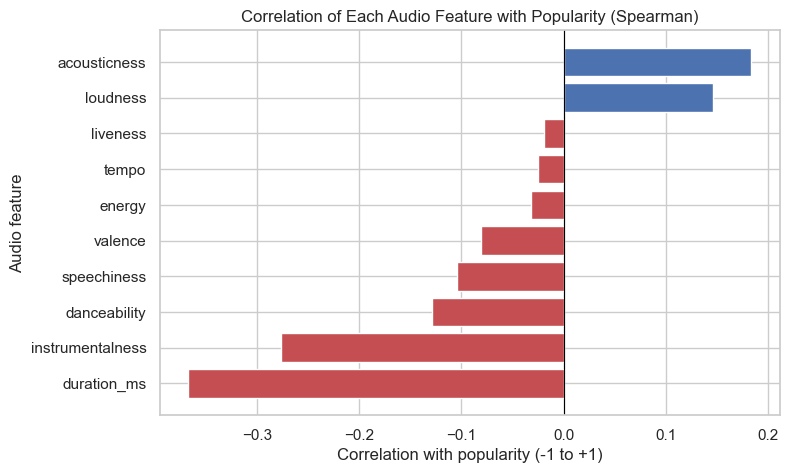

duration_ms        -0.368
instrumentalness   -0.276
danceability       -0.129
speechiness        -0.105
valence            -0.081
energy             -0.032
tempo              -0.025
liveness           -0.019
loudness            0.146
acousticness        0.184
Name: popularity, dtype: float64


In [118]:
corr = (df[features + ["popularity"]].corr(method="spearman")["popularity"]
        .drop("popularity").sort_values())

plt.figure(figsize=(8, 5))
plt.barh(corr.index, corr.values, color=["#C44E52" if v < 0 else "#4C72B0" for v in corr])
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Correlation of Each Audio Feature with Popularity (Spearman)")
plt.xlabel("Correlation with popularity (-1 to +1)")
plt.ylabel("Audio feature")
plt.show()
print(corr.round(3))

**What this shows:**

The correlation analysis indicates that none of the audio features exhibits a strong association with track popularity. Duration has the strongest negative relationship (r = −0.37), followed by instrumentalness (r = −0.28), suggesting that longer and more instrumental tracks tend to be associated with lower popularity scores. Acousticness (r = 0.18) and loudness (r = 0.15) exhibit weak positive associations, while tempo, energy and liveness have correlations close to zero (within 0.03 of zero), indicating negligible relationships with popularity.

These findings suggest that the streaming service should not rely on any single audio feature when selecting tracks for promotion, as no individual feature demonstrates a sufficiently strong relationship with popularity. Furthermore, popularity predictions based solely on audio features are expected to be relatively weak, indicating that other factors beyond audio characteristics are likely to play a more substantial role in explaining differences in track popularity.


### Chart 3: Popularity by instrumentalness

Instrumentalness was the biggest difference between the low and high groups (0.46 vs 0.02), and this is the picture of it. Bands make the pattern easy for a non-technical reader.

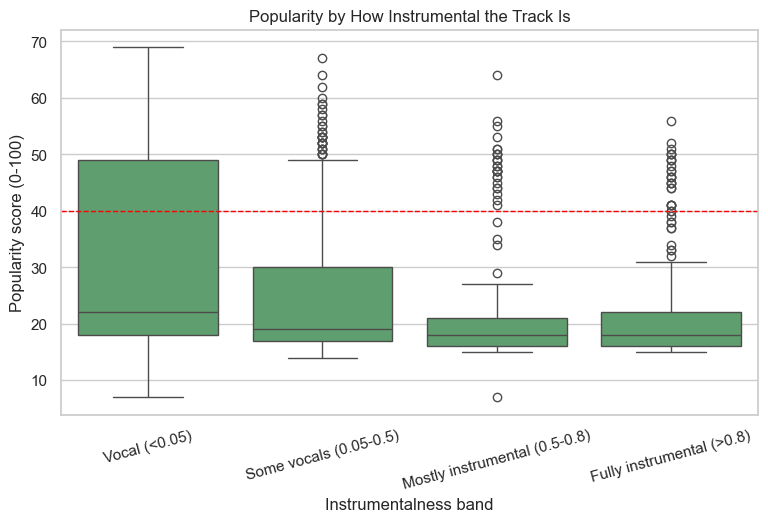

                               tracks  median_pop  share_at_40_plus
instrumentalness                                                   
Vocal (<0.05)                     348        22.0              0.39
Some vocals (0.05-0.5)            207        19.0              0.22
Mostly instrumental (0.5-0.8)     188        18.0              0.14
Fully instrumental (>0.8)         210        18.0              0.12


In [119]:
bands = pd.cut(df.instrumentalness, [-0.001, 0.05, 0.5, 0.8, 1.0],
               labels=["Vocal (<0.05)", "Some vocals (0.05-0.5)", "Mostly instrumental (0.5-0.8)", "Fully instrumental (>0.8)"])

plt.figure(figsize=(9, 5))
sns.boxplot(x=bands, y=df.popularity, color="#55A868")
plt.axhline(40, color="red", linestyle="--", linewidth=1)
plt.title("Popularity by How Instrumental the Track Is")
plt.xlabel("Instrumentalness band")
plt.ylabel("Popularity score (0-100)")
plt.xticks(rotation=15); plt.show()

print(df.groupby(bands, observed=True).agg(tracks=("popularity", "count"),
      median_pop=("popularity", "median"),
      share_at_40_plus=("popularity", lambda s: round((s >= 40).mean(), 3))).round(2))

**What this shows:**

Median popularity is similar in every band (22 for vocal tracks, then 19, 18 and 18), but the chance of reaching 40 or above is not: 39% of vocal tracks do, against 22% of tracks with some vocals, 14% of mostly instrumental tracks and 12% of fully instrumental ones. Popular instrumental tracks exist, but they are exceptions. This means the streaming service should treat vocal and instrumental drum-and-bass as different audiences, and should not expect an instrumental track to reach the popularity of a vocal single.

### Chart 4: How much does the artist matter?

This supports the decision to keep each artist on one side of the train/test split and shows whether popularity is about the track or the act.

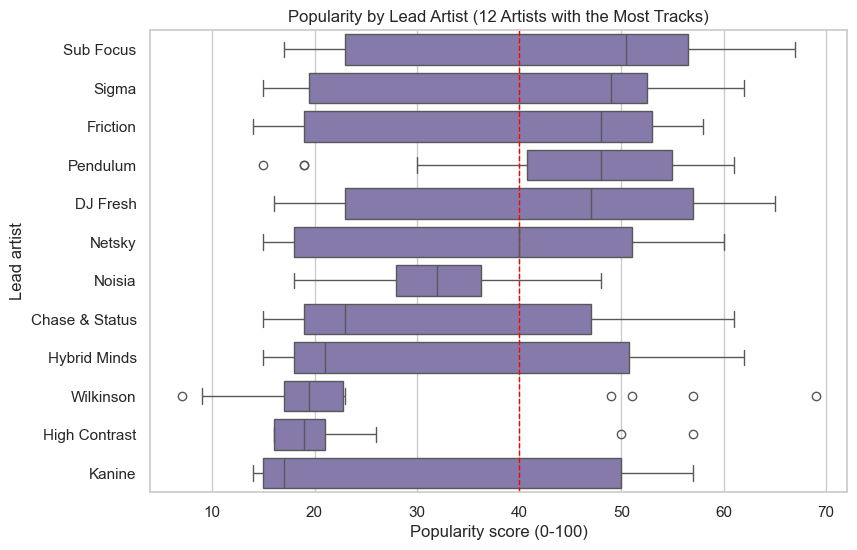

                count  median  min  max
lead_artist                            
Sub Focus          20    50.5   17   67
Sigma              15    49.0   15   62
Friction           19    48.0   14   58
Pendulum           28    48.0   15   61
DJ Fresh           17    47.0   16   65
Netsky             25    40.0   15   60
Noisia             16    32.0   18   48
Chase & Status     37    23.0   15   61
Hybrid Minds       22    21.0   15   62
Wilkinson          18    19.5    7   69
High Contrast      17    19.0   16   57
Kanine             15    17.0   14   57


In [120]:
top = df.lead_artist.value_counts().head(12).index
sub = df[df.lead_artist.isin(top)]
order = sub.groupby("lead_artist").popularity.median().sort_values(ascending=False).index

plt.figure(figsize=(9, 6))
sns.boxplot(data=sub, y="lead_artist", x="popularity", order=order, color="#8172B2")
plt.axvline(40, color="red", linestyle="--", linewidth=1)
plt.title("Popularity by Lead Artist (12 Artists with the Most Tracks)")
plt.xlabel("Popularity score (0-100)")
plt.ylabel("Lead artist")
plt.show()

print(sub.groupby("lead_artist").popularity.agg(["count", "median", "min", "max"])
      .sort_values("median", ascending=False))

**What this shows:**

Artists differ in typical popularity, from a median of 50.5 for Sub Focus to 17 for Kanine. But all 12 artists have tracks on both sides of the hit line. Wilkinson ranges from 7 to 69 and Chase & Status from 15 to 61, so even popular artists have unpopular tracks and the reverse. This means the streaming service should judge each track on its own and not promote a track just because its artist has other popular ones.

---
## Part 4 — Predict popularity
**Week 5**

### 4.1 Choose our inputs and target

`y` is what we are predicting: `popularity`.
`X` is what we are allowed to use — the audio features.
We used the name model_features so it doesn't clash with the earlier list, which has duration_ms.

In [121]:
model_features = ["danceability", "energy", "loudness", "speechiness", "acousticness",
                  "instrumentalness", "liveness", "valence", "tempo", "duration_min"]

d = df.copy()
X = d[model_features]
y = d["popularity"]

assert "popularity" not in X.columns and "is_hit" not in X.columns, "LEAKAGE"
print("Inputs:", list(X.columns))
print("Tracks:", len(X))

Inputs: ['danceability', 'energy', 'loudness', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'duration_min']
Tracks: 953


### 4.2 Split it, keeping artists apart

80% to learn from, 20% held back to score honestly. Every artist goes entirely into one side, so the model can't score well by recognising an artist (Chart 4 shows artists differ in typical popularity).

In [122]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
train_idx, test_idx = next(gss.split(d, groups=d.lead_artist))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

print(f"Train: {len(X_train)} tracks   Test: {len(X_test)} tracks")
print("Artists in both train and test:",
      len(set(d.lead_artist.iloc[train_idx]) & set(d.lead_artist.iloc[test_idx])))   # must be 0
print("Mean popularity  train / test:", round(y_train.mean(), 1), "/", round(y_test.mean(), 1))
print("Share at 40+     train / test:", round((y_train >= 40).mean(), 3), "/", round((y_test >= 40).mean(), 3))


Train: 786 tracks   Test: 167 tracks
Artists in both train and test: 0
Mean popularity  train / test: 26.0 / 30.2
Share at 40+     train / test: 0.224 / 0.353


### 4.3 Baseline and Model 1: Linear Regression

The baseline always predicts the average, so you can see whether either model beats guessing. Linear regression is simple and its coefficients can be read directly.

In [123]:
from sklearn.dummy import DummyRegressor

def rmse(a, b): return np.sqrt(mean_squared_error(a, b))

base = DummyRegressor().fit(X_train, y_train)
lin = LinearRegression().fit(X_train, y_train)
pred_base, pred_lin = base.predict(X_test), lin.predict(X_test)

print(f"Baseline (average)  RMSE {rmse(y_test, pred_base):.2f}   R2 {r2_score(y_test, pred_base):.3f}")
print(f"Linear Regression   RMSE {rmse(y_test, pred_lin):.2f}   R2 {r2_score(y_test, pred_lin):.3f}")

Baseline (average)  RMSE 15.80   R2 -0.074
Linear Regression   RMSE 13.52   R2 0.214


### 4.4 Read the coefficients

Each coefficient says: *if this feature goes up by one, the predicted popularity changes by this much.*


In [124]:
step = {"danceability": 0.1, "energy": 0.1, "loudness": 1, "speechiness": 0.1, "acousticness": 0.1,
        "instrumentalness": 0.1, "liveness": 0.1, "valence": 0.1, "tempo": 10, "duration_min": 1}
unit = {"loudness": "+1 dB", "tempo": "+10 BPM", "duration_min": "+1 minute"}

coefs = pd.DataFrame({
    "if the feature goes up by": [unit.get(f, "+0.1") for f in model_features],
    "predicted popularity changes by": [round(lin.coef_[i] * step[f], 2) for i, f in enumerate(model_features)]
}, index=model_features).sort_values("predicted popularity changes by")
display(coefs)

,if the feature goes up by,predicted popularity changes by
duration_min,+1 minute,-2.72
danceability,+0.1,-1.47
speechiness,+0.1,-1.11
instrumentalness,+0.1,-0.69
valence,+0.1,-0.42
liveness,+0.1,-0.20
energy,+0.1,0.03
tempo,+10 BPM,0.31
loudness,+1 dB,0.48
acousticness,+0.1,3.11


In [125]:
std = X_train.std()
effect = pd.Series(lin.coef_ * std.values, index=model_features).sort_values()
display(pd.DataFrame({"popularity change for +1 standard deviation": effect.round(2),
                      "1 standard deviation =": std.round(3)}))

,popularity change for +1 standard deviation,1 standard deviation =
acousticness,1.79,0.058
danceability,-1.71,0.116
duration_min,-3.10,1.140
energy,0.03,0.104
instrumentalness,-2.51,0.365
liveness,-0.36,0.182
loudness,1.17,2.447
speechiness,-0.88,0.079
tempo,0.54,17.198
valence,-0.94,0.224


**How to read the coefficients.** The first table above uses realistic steps for each feature. The second table compares features fairly: it shows how much predicted popularity changes when a feature goes up by one standard deviation. 

A track that is about 1.1 minutes longer than usual has about 3.1 fewer predicted popularity points, all other things being equal. Next is instrumentalness, with about 2.5 fewer points for each 0.37 rise on its 0-to-1 scale. Longer drum-and-bass tracks tend to be instrumental DJ-style cuts, so the two overlap and the model shares the credit between them. 

### 4.5 Model 2 — Random Forest

More flexible. It can pick up curves and combinations that a straight line cannot. The trade-off is that you lose the clean coefficient story.

In [126]:
from sklearn.inspection import permutation_importance

rf = RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1)
rf.fit(X_train, y_train)
pred_rf = rf.predict(X_test)

print(f"Random Forest       RMSE {rmse(y_test, pred_rf):.2f}   R2 {r2_score(y_test, pred_rf):.3f}")

imp = permutation_importance(rf, X_test, y_test, n_repeats=20, random_state=RANDOM_STATE, n_jobs=-1)
display(pd.Series(imp.importances_mean, index=model_features)
        .sort_values(ascending=False).round(3).rename("drop in R2 if shuffled").to_frame())

Random Forest       RMSE 13.12   R2 0.260


,drop in R2 if shuffled
duration_min,0.256
instrumentalness,0.096
danceability,0.031
acousticness,0.030
speechiness,0.020
valence,0.018
liveness,0.016
loudness,0.015
tempo,0.000
energy,0.000


### Does one feature work alone? (diagnostic check)

The table above shows duration and instrumentalness matter most inside the random forest. This check tests whether they predict popularity on their own. It is only used to explain the result: our two reported models use all ten features and we did not choose features by their test score.

In [127]:
for cols in (["duration_min"], ["duration_min", "instrumentalness"], model_features):
    m = RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1).fit(X_train[cols], y_train)
    print(f"{len(cols):>2} feature(s) {str(cols)[:60]:<62} test R2 {r2_score(y_test, m.predict(X_test[cols])):.3f}")

 1 feature(s) ['duration_min']                                               test R2 -0.213
 2 feature(s) ['duration_min', 'instrumentalness']                           test R2 0.037
10 feature(s) ['danceability', 'energy', 'loudness', 'speechiness', 'acous   test R2 0.260


Duration on its own scored worse than guessing the average (R² of -0.21), and duration plus instrumentalness reached only 0.04. The score of 0.26 appears only when all ten features are used together. So no single feature or pair explains popularity here: the signal is spread thinly across many features, which fits the low R² we report. 

A model trained on duration alone may also memorise the track lengths of artists it has seen, which fails on artists it has not (the test set only contains unseen artists). These numbers come from one split, so they are for explanation only.

### 4.6 Compare, and plot predicted against actual

Lower RMSE is better. Higher R-squared is better. Points on the diagonal are perfect predictions.

If your points form a flat blob rather than a diagonal line, your model is barely doing better than guessing the average. Say that plainly — it is the honest reading.

,Model,RMSE (test),R2 (test)
0,Baseline (average),15.802,-0.074
1,Linear Regression,13.518,0.214
2,Random Forest,13.116,0.260


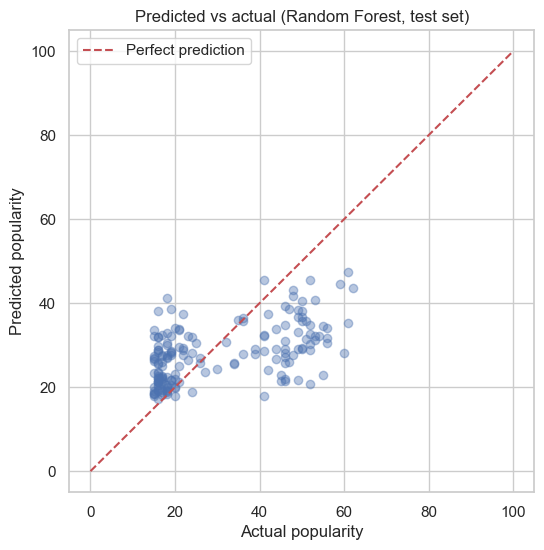

Over 10 splits - Linear: mean R2 0.177 (worst -0.022, best 0.278)
Over 10 splits - Forest: mean R2 0.183 (worst -0.001, best 0.298)


In [128]:
results = pd.DataFrame({
    "Model": ["Baseline (average)", "Linear Regression", "Random Forest"],
    "RMSE (test)": [rmse(y_test, p) for p in (pred_base, pred_lin, pred_rf)],
    "R2 (test)":   [r2_score(y_test, p) for p in (pred_base, pred_lin, pred_rf)]}).round(3)
display(results)

best_name, best = ("Random Forest", pred_rf) if rmse(y_test, pred_rf) < rmse(y_test, pred_lin) else ("Linear Regression", pred_lin)
plt.figure(figsize=(6, 6))
plt.scatter(y_test, best, alpha=0.4)
plt.plot([0, 100], [0, 100], "r--", label="Perfect prediction")
plt.xlabel("Actual popularity"); plt.ylabel("Predicted popularity")
plt.title(f"Predicted vs actual ({best_name}, test set)")
plt.legend(); plt.show()

# Is this one split typical? Ten different artist splits
g10 = GroupShuffleSplit(n_splits=10, test_size=0.2, random_state=RANDOM_STATE)
r_lin, r_rf = [], []
for tr, te in g10.split(d, groups=d.lead_artist):
    r_lin.append(r2_score(y.iloc[te], LinearRegression().fit(X.iloc[tr], y.iloc[tr]).predict(X.iloc[te])))
    r_rf.append(r2_score(y.iloc[te], RandomForestRegressor(n_estimators=150, random_state=RANDOM_STATE, n_jobs=-1)
                         .fit(X.iloc[tr], y.iloc[tr]).predict(X.iloc[te])))
print(f"Over 10 splits - Linear: mean R2 {np.mean(r_lin):.3f} (worst {np.min(r_lin):.3f}, best {np.max(r_lin):.3f})")
print(f"Over 10 splits - Forest: mean R2 {np.mean(r_rf):.3f} (worst {np.min(r_rf):.3f}, best {np.max(r_rf):.3f})")

### Part 4: Write

1. Our best model, the random forest, predicts popularity to within about 13 points on the 0-to-100 scale (RMSE 13.1 on 167 test tracks from artists it never saw). Always guessing the average is off by about 15.8.

2. On this test set it explains about 26% of the variation in popularity. Across ten different artist splits it averages 18% (from about 0% to 30%), and linear regression does almost the same (18%, from -2% to 28%), so the two models are effectively tied. We trust the ten-split average, because this test set happened to contain more popular tracks than the training set.

3. **This means the streaming service should** not use audio features on their own to decide which drum-and-bass tracks to promote. At best they are a weak extra signal to use alongside artist, release and playlist information.

Why the score is low: marketing spend, playlist placement, the artist's fanbase and release timing are not in the data. No single feature works alone either: track length on its own scored worse than guessing (R² of -0.21) and only the ten features together reached 0.26 on this split. The models may also be picking up the type of release (radio edit or club cut) more than the sound.

---
## Part 5 — Spot the hits
**Week 6**

Now you are predicting a category — hit or not — instead of a number.

**Check for leakage first.** `is_hit` was made from `popularity`. If `popularity` is in your inputs, the model reads the answer and scores near 100%. That result is worthless.

### 5.1 Inputs and target, with no leakage

In [129]:
Xc = d[model_features]
yc = d["is_hit"]

banned = ["popularity", "is_hit"]
assert not any(c in banned for c in Xc.columns), "LEAKAGE - remove popularity"
print("No leakage. Inputs:", list(Xc.columns))
print(f"Hits: {yc.sum()} of {len(yc)} ({yc.mean():.1%})")

No leakage. Inputs: ['danceability', 'energy', 'loudness', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'duration_min']
Hits: 235 of 953 (24.7%)


### 5.2 Split and scale

In [130]:
from sklearn.model_selection import StratifiedGroupKFold


sgk = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
tr, te = next(sgk.split(Xc, yc, groups=d.lead_artist))

Xc_train, Xc_test = Xc.iloc[tr], Xc.iloc[te]
yc_train, yc_test = yc.iloc[tr], yc.iloc[te]

scaler = StandardScaler().fit(Xc_train)
Xc_train_s, Xc_test_s = scaler.transform(Xc_train), scaler.transform(Xc_test)

print(f"Train: {len(Xc_train)}   Test: {len(Xc_test)}")
print("Artists in both train and test:", len(set(d.lead_artist.iloc[tr]) & set(d.lead_artist.iloc[te])))   # must be 0
print("Share of hits - train:", yc_train.mean().round(3), " test:", yc_test.mean().round(3))


Train: 658   Test: 295
Artists in both train and test: 0
Share of hits - train: 0.225  test: 0.295


### 5.3 Baseline and two models

In [131]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

base_c = DummyClassifier(strategy="most_frequent").fit(Xc_train, yc_train)
log = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE).fit(Xc_train_s, yc_train)
tree = DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE).fit(Xc_train, yc_train)

preds = {"Baseline (always 'not a hit')": base_c.predict(Xc_test),
         "Logistic Regression": log.predict(Xc_test_s),
         "Decision Tree": tree.predict(Xc_test)}

for name, p in preds.items():
    print(f"{name:32s} accuracy {accuracy_score(yc_test, p):.2f}  "
          f"precision {precision_score(yc_test, p, zero_division=0):.2f}  "
          f"recall {recall_score(yc_test, p, zero_division=0):.2f}")

Baseline (always 'not a hit')    accuracy 0.71  precision 0.00  recall 0.00
Logistic Regression              accuracy 0.77  precision 0.86  recall 0.28
Decision Tree                    accuracy 0.73  precision 0.59  recall 0.31


### 5.4 The confusion matrix

Accuracy hides *which* mistakes you make. This does not.

|  | Predicted not a hit | Predicted a hit |
|---|---|---|
| **Actually not a hit** | correct | **wasted promotion** |
| **Actually a hit** | **missed opportunity** | correct |

For a streaming service deciding which tracks to promote, those two errors cost very different amounts. Promoting a dud wastes budget. Missing a hit means a rival playlists it first. Which matters more to you?

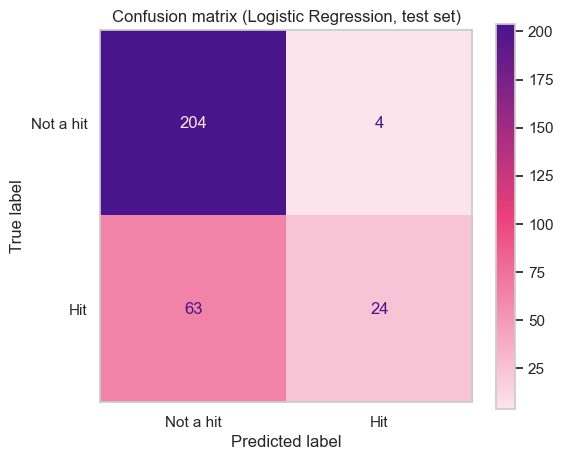

Logistic Regression  real hits: 87 | caught: 24 | missed: 63 | wrongly called a hit: 4
Decision Tree        real hits: 87 | caught: 27 | missed: 60 | wrongly called a hit: 19


In [132]:


from sklearn.metrics import f1_score
from matplotlib.colors import LinearSegmentedColormap

best_c = max(["Logistic Regression", "Decision Tree"], key=lambda n: f1_score(yc_test, preds[n]))

berry = LinearSegmentedColormap.from_list("berry", ["#FCE4EC", "#EC407A", "#4A148C"])

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    yc_test, preds[best_c],
    display_labels=["Not a hit", "Hit"],
    cmap=berry,
    values_format="d",
    ax=ax)
ax.grid(False)
ax.set_title(f"Confusion matrix ({best_c}, test set)")
plt.show()

for name in ["Logistic Regression", "Decision Tree"]:
    tn, fp, fn, tp = confusion_matrix(yc_test, preds[name]).ravel()
    print(f"{name:20s} real hits: {tp + fn} | caught: {tp} | missed: {fn} | wrongly called a hit: {fp}")

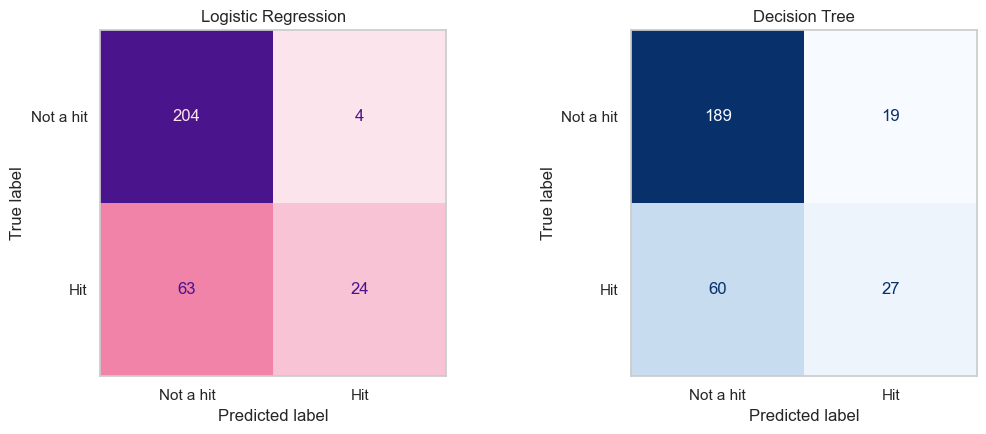

In [133]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

for ax, name in zip(axes, ["Logistic Regression", "Decision Tree"]):

    # Keep berry for Logistic Regression; use light blues for Decision Tree
    cmap_used = berry if name == "Logistic Regression" else "Blues"

    ConfusionMatrixDisplay.from_predictions(
        yc_test,
        preds[name],
        display_labels=["Not a hit", "Hit"],
        cmap=cmap_used,
        values_format="d",
        colorbar=False,
        ax=ax
    )

    ax.grid(False)
    ax.set_title(name)

plt.tight_layout()
plt.show()

In [134]:
from sklearn.model_selection import cross_validate, StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import make_scorer, precision_score, recall_score

cv5 = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

models = {
    "Baseline (always 'not a hit')": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": make_pipeline(StandardScaler(),
                                         LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    "Decision Tree": DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE),
}

scoring = {"accuracy": "accuracy",
           "precision": make_scorer(precision_score, zero_division=0),
           "recall": make_scorer(recall_score, zero_division=0)}

rows = []
for name, m in models.items():
    r = cross_validate(m, Xc, yc, cv=cv5, groups=d.lead_artist, scoring=scoring)
    rows.append((name,
                 round(r["test_accuracy"].mean(), 2),
                 round(r["test_precision"].mean(), 2),
                 round(r["test_recall"].mean(), 2)))

display(pd.DataFrame(rows, columns=["Model", "accuracy", "precision", "recall"]))

,Model,accuracy,precision,recall
0,Baseline (always 'not a hit'),0.77,0.00,0.00
1,Logistic Regression,0.78,0.57,0.30
2,Decision Tree,0.74,0.44,0.34


### Part 5: Write

1. On our test split, 87 tracks were real hits. Logistic regression missed 63 of them (72%) and the decision tree missed 60. Over five artist-grouped tests, logistic regression finds about 30% of real hits, so about 7 in 10 are missed.

2. Logistic regression wrongly called 4 non-hits a hit, and the decision tree wrongly called 19. Over five tests, a track the logistic model flags really is a hit 57% of the time (decision tree: 44%).

3. A wasted promotion spends budget on a track that flops. A missed hit means a rival playlists it first. With limited promotion slots, wasted promotions are the easier cost to control, so we prefer the more precise logistic regression. But with recall of only 30%, either model leaves most hits unspotted.

4. **This means the streaming service should** use the model only as a cautious shortlist, since the tracks it flags are about twice as likely to be hits as a random pick (57% against 25%), and not rely on audio alone to find hits, because about 7 in 10 are missed.

Accuracy is close to the baseline (0.78 against 0.77 for always saying "not a hit"), which is why we also report precision and recall. It is nowhere near 1.00, and `popularity` is not among the inputs, so there is no leakage.

---
## Part 6 — Find the moods
**Week 7**

### 6.1 Pick your two columns and scale them

In [135]:
from sklearn.cluster import KMeans

mood_cols = ["valence", "energy"]
Xm = d[mood_cols]
Xm_scaled = StandardScaler().fit_transform(Xm)

print("Clustering", len(Xm), "tracks on:", mood_cols)
display(Xm.describe().round(2))

Clustering 953 tracks on: ['valence', 'energy']


,valence,energy
count,953.00,953.00
mean,0.32,0.88
std,0.23,0.11
min,0.03,0.38
25%,0.12,0.83
50%,0.28,0.90
75%,0.46,0.96
max,0.97,1.00


### 6.2 How many groups? The elbow plot

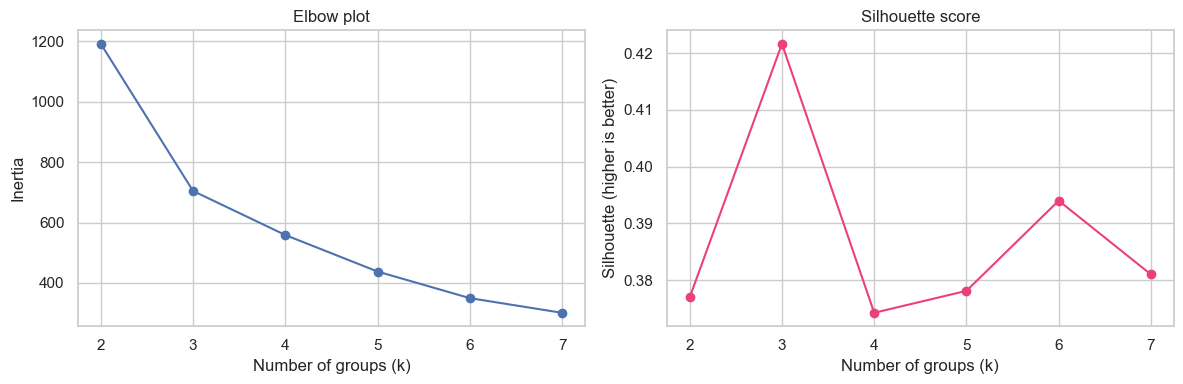

   k  inertia  silhouette
0  2   1191.5       0.377
1  3    704.6       0.422
2  4    558.8       0.374
3  5    437.9       0.378
4  6    349.9       0.394
5  7    301.3       0.381


In [136]:
inertias, sils = [], []
ks = range(2, 8)
for k in ks:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10).fit(Xm_scaled)
    inertias.append(km.inertia_)
    sils.append(silhouette_score(Xm_scaled, km.labels_))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(list(ks), inertias, marker="o"); ax[0].set(title="Elbow plot", xlabel="Number of groups (k)", ylabel="Inertia")
ax[1].plot(list(ks), sils, marker="o", color="#EC407A"); ax[1].set(title="Silhouette score", xlabel="Number of groups (k)", ylabel="Silhouette (higher is better)")
plt.tight_layout(); plt.show()
print(pd.DataFrame({"k": list(ks), "inertia": np.round(inertias, 1), "silhouette": np.round(sils, 3)}))

### 6.3 Fit and plot your mood groups

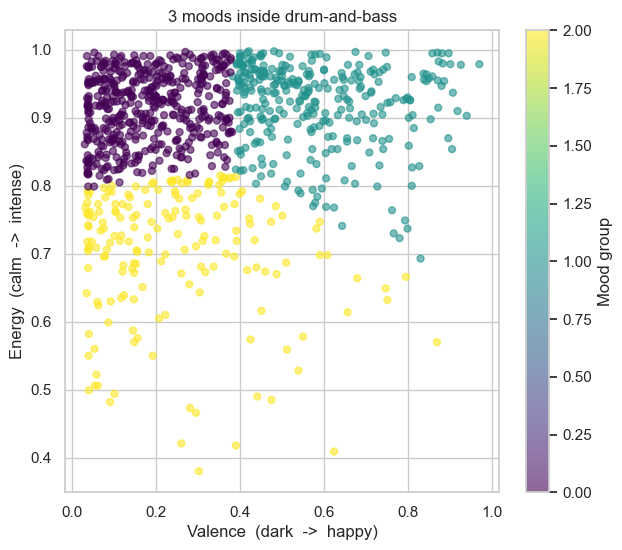

In [137]:
K = 3    #choice from 6.2 above, based on the elbow and silhoutete score

km = KMeans(n_clusters=K, random_state=RANDOM_STATE, n_init=10)
d["mood"] = km.fit_predict(Xm_scaled)

plt.figure(figsize=(7, 6))
sc = plt.scatter(d["valence"], d["energy"], c=d["mood"], cmap="viridis", s=25, alpha=0.6)
plt.xlabel("Valence  (dark  ->  happy)")
plt.ylabel("Energy  (calm  ->  intense)")
plt.title(f"{K} moods inside drum-and-bass")
plt.colorbar(sc, label="Mood group")
plt.show()

### 6.4 What is each mood like?

In [138]:
profile = d.groupby("mood")[["valence", "energy", "danceability", "instrumentalness", "duration_min", "popularity"]].mean()
profile["n_tracks"] = d.groupby("mood").size()
profile["share_hits"] = d.groupby("mood").is_hit.mean()
display(profile.round(2))

for m in sorted(d["mood"].unique()):
    sample = d[d["mood"] == m].sample(4, random_state=RANDOM_STATE)
    print(f"\nMood {m}:")
    for _, r in sample.iterrows():
        print("   ", r.track_name[:45], "-", r.lead_artist)

,valence,energy,danceability,instrumentalness,duration_min,popularity,n_tracks,share_hits
mood,,,,,,,,
0,0.18,0.91,0.49,0.43,4.63,28.29,468,0.29
1,0.58,0.92,0.59,0.35,4.52,24.61,305,0.18
2,0.24,0.70,0.56,0.33,4.66,26.48,180,0.23



Mood 0:
    Vendetta (A.M.C & Turno Remix) - DC Breaks
    All Over You - The Upbeats
    Self vs Self (feat. In Flames) - Pendulum
    Inner Space - Original Mix - Apex

Mood 1:
    Share The Fall - Full Vocal Mix - Roni Size
    Squad Up - Netsky
    Barricades (with Rita Ora) - Shapes Remix - Netsky
    The Light - TC

Mood 2:
    Flashing Lights - Chase & Status
    Thank You - Mixed - Ed Solo
    In My Mind - Document One
    These Things VIP - Jubei


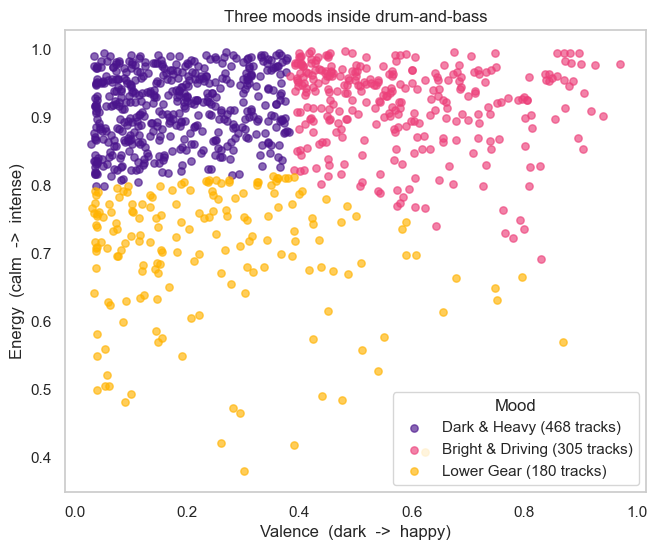

In [139]:
names = {0: "Dark & Heavy", 1: "Bright & Driving", 2: "Lower Gear"}
colors = {0: "#4A148C", 1: "#EC407A", 2: "#FFB300"}

fig, ax = plt.subplots(figsize=(7.5, 6))
for m, label in names.items():
    s = d[d.mood == m]
    ax.scatter(s.valence, s.energy, s=28, alpha=0.65, color=colors[m], label=f"{label} ({len(s)} tracks)")
ax.set_xlabel("Valence  (dark  ->  happy)")
ax.set_ylabel("Energy  (calm  ->  intense)")
ax.set_title("Three moods inside drum-and-bass")
ax.grid(False)
ax.legend(title="Mood")
plt.show()

### Part 6: Write: name your moods

| Group | Your name for it | Valence | Energy | Average popularity |
|---|---|---|---|---|
| 0 | Dark & Heavy | 0.18 | 0.91 | 28.3 |
| 1 | Bright & Driving | 0.58 | 0.92 | 24.6 |
| 2 | Lower Gear | 0.24 | 0.70 | 26.5 |



**Why K = 3:** the elbow plot bends at 3 (the spread within groups falls 41% from 2 to 3 groups, then only 14 to 22% per step) and 3 has the highest silhouette score (0.42, against 0.37 to 0.39 for other values; closer to 1 is better). The score is moderate and the plot shows one continuous cloud of tracks, so the groups are a useful way to divide the genre, not sharply separate clusters.

**How we named them:** from the averages and sample tracks. Dark & Heavy (468 tracks, 49%) is the darkest and includes Pendulum's "Self vs Self". Bright & Driving (305, 32%) is the happiest and most danceable and includes vocal tracks such as Netsky's "Barricades". Lower Gear (180, 19%) has noticeably lower energy and includes Chase & Status's "Flashing Lights". Dark & Heavy performs best: 29% of its tracks reach popularity 40 or more, against 23% for Lower Gear and 18% for Bright & Driving. The differences are modest, so we treat them as suggestive.

**This means the streaming service should** build separate drum-and-bass playlists around these three moods, and test promotions on the Dark & Heavy mood first, treating the first results as an experiment and not a rule.

---
## Part 7 — Tune your model
**Week 7**

Grid Search tries several settings and keeps the best.

### 7.1 Try different settings

In [140]:
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold

grid = {"max_depth": [2, 3, 4, 5, 6, 8, 12],
        "min_samples_leaf": [1, 5, 10, 20]}

groups_train = d.lead_artist.loc[Xc_train.index]
inner_cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

search = GridSearchCV(DecisionTreeClassifier(random_state=RANDOM_STATE),
                      grid, cv=inner_cv, scoring="f1")
search.fit(Xc_train, yc_train, groups=groups_train)

print("Best settings:", search.best_params_)
print("Best cross-validated F1 (training data only):", round(search.best_score_, 3))

top = (pd.DataFrame(search.cv_results_)
       [["param_max_depth", "param_min_samples_leaf", "mean_test_score", "std_test_score"]]
       .sort_values("mean_test_score", ascending=False).head(8).round(3))
display(top)

Best settings: {'max_depth': 12, 'min_samples_leaf': 1}
Best cross-validated F1 (training data only): 0.382


,param_max_depth,param_min_samples_leaf,mean_test_score,std_test_score
24,12,1,0.382,0.040
12,5,1,0.356,0.086
20,8,1,0.348,0.039
13,5,5,0.343,0.101
16,6,1,0.336,0.094
17,6,5,0.335,0.096
18,6,10,0.329,0.112
26,12,10,0.312,0.090


### Which setting mattered most?

The Grid Search tried 7 tree depths and 4 minimum leaf sizes (28 combinations). This averages the cross-validated F1 score over each setting, so we can see which of the two moved the score more.

In [141]:
res = pd.DataFrame(search.cv_results_)
print(res.groupby("param_min_samples_leaf").mean_test_score.mean().round(3))
print(res.groupby("param_max_depth").mean_test_score.mean().round(3))

param_min_samples_leaf
1     0.299
5     0.280
10    0.274
20    0.278
Name: mean_test_score, dtype: float64
param_max_depth
2     0.257
3     0.198
4     0.258
5     0.319
6     0.320
8     0.310
12    0.318
Name: mean_test_score, dtype: float64


Tree depth mattered most. The average cross-validated F1 was 0.20 to 0.26 for trees with 2 to 4 levels of questions and 0.31 to 0.32 for trees with 5 or more, whereas the minimum leaf size barely changed the score (0.27 to 0.30 across all four values). The tree's depth is how many yes-or-no questions it can ask in a row before deciding and the leaf size is the smallest number of tracks allowed in a final answer. Depths 5 to 12 scored almost the same, so a simpler tree would do about as well as the depth-12 tree we selected.

### 7.2 Before and after

In [142]:
tuned = search.best_estimator_
pred_before = preds["Decision Tree"]
pred_after = tuned.predict(Xc_test)

rows = []
for name, p in [("Before tuning (depth 4)", pred_before), (f"After tuning {search.best_params_}", pred_after)]:
    rows.append((name, round(accuracy_score(yc_test, p), 3),
                 round(precision_score(yc_test, p, zero_division=0), 3),
                 round(recall_score(yc_test, p, zero_division=0), 3),
                 round(f1_score(yc_test, p), 3)))
display(pd.DataFrame(rows, columns=["Tree", "accuracy", "precision", "recall", "F1"]))
print("Baseline accuracy (always 'not a hit'):", round(1 - yc_test.mean(), 3))

,Tree,accuracy,precision,recall,F1
0,Before tuning (depth 4),0.732,0.587,0.310,0.406
1,"After tuning {'max_depth': 12, 'min_samples_leaf': 1}",0.702,0.493,0.425,0.457


Baseline accuracy (always 'not a hit'): 0.705


### Part 7: Write

1. Tree depth mattered most. The average cross-validated F1 was 0.20 to 0.26 for trees with 2 to 4 levels of questions and 0.31 to 0.32 for trees with 5 or more, whereas the minimum leaf size barely changed the score (0.27 to 0.30 across all four values). The tree's depth is how many yes-or-no questions it can ask in a row before deciding, and the leaf size is the smallest number of tracks allowed in a final answer. Depths 5 to 12 averaged almost the same, so going deeper than about 5 or 6 levels added little on average. These are averages over the whole grid and the folds vary a lot, so small differences should not be over-read. 

2. Tuning did not clearly help. The tuned tree (depth 12, leaf size 1) caught more real hits (recall 0.31 to 0.43) but wrongly flagged more tracks (precision 0.59 to 0.49). F1 rose from 0.41 to 0.46, a gain about as large as the variation between folds, and accuracy fell from 0.73 to 0.70, no better than always saying "not a hit" (0.71). Tuning changed the balance more than the quality.

3. With another month we would add artist, label and release-date data, since audio alone is a weak signal; test a different hit line such as the genre median; check the mood names by listening; and widen the Grid Search beyond depth 12, because the best setting sat at the edge of our grid.

**This means the streaming service should** not expect tuning to fix a weak signal. The tuned tree finds more hits but wastes more promotions, so the choice between the tuned and the simple tree depends on whether a wasted promotion or a missed hit costs the service more.